# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Análisis Exploratorio: Ingreso de Viajeros Internacionales a Guatemala

**Curso:** CC3084 · **Ejercicio 1 — Análisis Exploratorio de Datos (EDA)**

Este notebook explora el histórico mensual de ingreso de viajeros internacionales a
Guatemala (`data/raw/Base_Migracion_2009-2026jun.xlsx`). Cada sección está rotulada con
el **inciso del rubro (a–f)** que satisface, y toda interpretación está fundamentada en
los resultados numéricos y gráficos producidos por las propias celdas.

### Contexto del conjunto de datos
- Formato **largo/tidy**: una fila por combinación de mes · vía · frontera · país/agrupación · tipo de viajero, con la **cantidad de viajeros** en la columna `Viajero`.
- Cobertura: **enero 2009 – junio 2026** (210 meses consecutivos). **⚠️ 2026 solo cubre enero–junio** (año parcial, no comparable con años completos).
- **Uso exclusivamente académico**: no son cifras oficiales.

### Definiciones de `Tipo de Viajero` (hoja *Notas*)
- **Turista**: pernocta al menos una noche.
- **Excursionista**: visita en el mismo día, sin pernoctar.
- **Viajero**: cruza la frontera pero **no** es visitante (trabajo fronterizo, tránsito, carga, tripulación, comercio de alta frecuencia).
- **Cruceristas**: pasajeros de crucero (solo hasta 2022).

### ⚠️ Rupturas estructurales a respetar
1. **Colapso pandémico** (marzo 2020) y piso 2020–2021.
2. **Cambio de metodología 2022→2023**: la categoría *Viajero* se reclasifica y cae fuertemente; además `País` pasa de país individual (hasta 2022) a **agrupaciones de mercado** (desde 2023).

> Para comparar de forma **consistente** en todo el rango se usa **Turista + Excursionista**,
> que sí son homogéneos durante todo el período.

## Configuración del entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display

# Estilo consistente y paleta apta para daltonismo (validada)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (9, 4.5),
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
PAL = sns.color_palette("colorblind")
MILES = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
pd.set_option("display.max_columns", 40)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 1. Carga de datos

In [2]:
RUTA = "../data/raw/Base_Migracion_2009-2026jun.xlsx"
df = pd.read_excel(RUTA, sheet_name="Datos")

print(f"Registros: {df.shape[0]:,}   |   Columnas: {df.shape[1]}")
display(df.dtypes.to_frame("tipo de dato"))
display(df.head())

Registros: 161,036   |   Columnas: 13


,tipo de dato
Año,int64
Mes cod,int64
Mes,str
Vía,str
Frontera,str
País,str
Región,str
Región dos,str
Regiones OMT,str
MCEO,str


,Año,Mes cod,Mes,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero
0,2009,1,Ene,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0
1,2009,1,Ene,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0
2,2009,1,Ene,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4.0
3,2009,1,Ene,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5.0
4,2009,1,Ene,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1.0


El archivo contiene **161,036 registros** y **13 columnas** en formato largo. Las
variables categóricas se cargan como texto y las medidas (`Año`, `Mes cod`, `Viajero`)
como numéricas. La columna `Viajero` es la **medida** a analizar; el resto son
dimensiones (tiempo, vía, frontera, país y clasificaciones geográficas).

## 2. Preparación de datos

Casteo de tipos, construcción de una columna `fecha`, normalización de `País` (para
corregir duplicados por mayúsculas) y definición de la **vista consistente**
`Turista + Excursionista`. *(Trabajo en memoria; no se exporta ningún archivo.)*

In [3]:
df["Año"]     = pd.to_numeric(df["Año"], errors="coerce")
df["Mes cod"] = pd.to_numeric(df["Mes cod"], errors="coerce")
df["Viajero"] = pd.to_numeric(df["Viajero"], errors="coerce")

# Fecha mensual (primer día de cada mes)
df["fecha"] = pd.to_datetime(dict(year=df["Año"], month=df["Mes cod"], day=1))

# País normalizado (corrige duplicados por casing)
df["Pais_norm"] = df["País"].str.strip().str.title()

# Vista consistente para todo el rango: excluye "Viajero" (alta frecuencia) y "Cruceristas"
CONSISTENTES = ["Turista", "Excursionista"]
vis = df[df["Tipo de Viajero"].isin(CONSISTENTES)].copy()

print(f"Periodo: {df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}  "
      f"({df['fecha'].nunique()} meses, sin huecos)")
print(f"Filas totales: {len(df):,}   |   Vista visitantes (Turista+Excursionista): {len(vis):,}")

Periodo: 2009-01 a 2026-06  (210 meses, sin huecos)
Filas totales: 161,036   |   Vista visitantes (Turista+Excursionista): 137,642


## 3. Calidad de datos — faltantes y duplicados  *(rubro e)*

In [4]:
# --- Valores faltantes ---
faltantes = df.isnull().sum()
print("Valores faltantes por columna:")
display(faltantes.to_frame("faltantes"))

# --- Duplicados exactos ---
print(f"Filas duplicadas exactas (13 columnas originales): "
      f"{df.duplicated(subset=df.columns[:13]).sum()}")

Valores faltantes por columna:


,faltantes
Año,0
Mes cod,0
Mes,0
Vía,0
Frontera,0
País,0
Región,0
Región dos,0
Regiones OMT,0
MCEO,0


Filas duplicadas exactas (13 columnas originales): 0


In [5]:
# --- Duplicados por mayúsculas/minúsculas en País ---
clave = df["País"].str.strip().str.lower()
variantes = df.assign(_k=clave).groupby("_k")["País"].unique()
casing = variantes[variantes.apply(len) > 1]

print(f"Países distintos (crudo): {df['País'].nunique()}  ->  "
      f"normalizado: {df['Pais_norm'].nunique()}")
print(f"Grupos con duplicado por casing: {len(casing)}\n")
display(casing.to_frame("variantes detectadas"))

Países distintos (crudo): 235  ->  normalizado: 222
Grupos con duplicado por casing: 13



,variantes detectadas
_k,
antigua y barbuda,"[Antigua y Barbuda, Antigua Y Barbuda]"
bolivia (estado plurinacional de),"[Bolivia (Estado Plurinacional de), Bolivia (E..."
côte d'ivoire,"[Côte d'Ivoire, Côte D'ivoire]"
federación de rusia,"[Federación de Rusia, Federación De Rusia]"
irán (república islámica del),"[Irán (República Islámica del), Irán (Repúblic..."
micronesia (estados federados de),"[Micronesia (Estados Federados de), Micronesia..."
otros paises del mundo,"[OTROS PAISES DEL MUNDO, Otros Paises Del Mundo]"
reino unido de gran bretaña e irlanda del norte,[Reino Unido de Gran Bretaña e Irlanda del Nor...
república de corea,"[República de Corea, República De Corea]"


In [6]:
# --- Valores anómalos en las clasificaciones geográficas ---
print("Categorías únicas en 'Región dos':")
print(sorted(df["Región dos"].unique()), "\n")

anom_omt = [v for v in df["Regiones OMT"].unique() if v in ("0", "0x2a", "SIN ESPECIFICAR")]
print("Valores anómalos en 'Regiones OMT':", anom_omt)

m0  = df["Región dos"] == "0"
mox = df["Regiones OMT"] == "0x2a"
msn = df["Regiones OMT"] == "SIN ESPECIFICAR"
print(f"\n'0' en Región dos:        {m0.sum():>4} filas | {df.loc[m0,'Viajero'].sum():>12,.0f} viajeros")
print(f"'0x2a' en Regiones OMT:   {mox.sum():>4} filas | {df.loc[mox,'Viajero'].sum():>12,.0f} viajeros")
print(f"'SIN ESPECIFICAR' en OMT: {msn.sum():>4} filas | {df.loc[msn,'Viajero'].sum():>12,.0f} viajeros")
print(f"\n'SIN ESPECIFICAR' corresponde principalmente a: "
      f"{df.loc[msn,'Tipo de Viajero'].value_counts().to_dict()}")

Categorías únicas en 'Región dos':
['0', 'América Del Centro', 'América Del Norte', 'América Del Sur y el Caribe', 'Asia', 'Cruceristas', 'Cruceros', 'Europa', 'Oceanía', 'Oriente Medio', 'Otros Paises Del Mundo'] 

Valores anómalos en 'Regiones OMT': ['SIN ESPECIFICAR', '0x2a']

'0' en Región dos:          13 filas |          821 viajeros
'0x2a' en Regiones OMT:      5 filas |           74 viajeros
'SIN ESPECIFICAR' en OMT:  196 filas |    1,078,372 viajeros

'SIN ESPECIFICAR' corresponde principalmente a: {'Cruceristas': 196}


**Interpretación (calidad):**
- **No hay valores faltantes** en ninguna columna, y **no existen filas duplicadas exactas** — el dataset está bien estructurado.
- Sin embargo, la calidad **no es perfecta**: `País` tiene **13 grupos de duplicados por mayúsculas/minúsculas** (p. ej. *Antigua Y Barbuda* vs *Antigua y Barbuda*), que inflan el conteo de **235 → 222** países. La columna normalizada `Pais_norm` corrige esto.
- Aparecen **categorías anómalas** en las clasificaciones geográficas:
  - `'0'` en `Región dos`: **13 filas** (821 viajeros) — residual, impacto despreciable.
  - `'0x2a'` en `Regiones OMT`: **5 filas** — artefacto de escape del carácter `*`.
  - `'SIN ESPECIFICAR'` en `Regiones OMT`: **196 filas (~1.08M viajeros)**, que corresponden casi en su totalidad a **Cruceristas** (no tienen subregión OMT asignada). No es un error de dato, sino ausencia legítima de subregión.
- En conjunto las anomalías afectan **~0.13%** de las filas; se documentan pero no distorsionan el análisis de visitantes (que usa Turista+Excursionista).

## 4. Estadísticas descriptivas  *(rubro f)*

In [7]:
print("Estadísticas de la medida 'Viajero':")
display(df["Viajero"].describe().to_frame().T)

print(f"Proporción de ceros:            {(df['Viajero']==0).mean()*100:.2f}%")
print(f"Proporción con decimales:       {(df['Viajero']%1!=0).mean()*100:.1f}%  "
      f"(expansiones de encuesta, no conteos exactos)")

resumen_tipo = (df.groupby("Tipo de Viajero")
                  .agg(registros=("Viajero","size"),
                       total_viajeros=("Viajero","sum"),
                       promedio=("Viajero","mean"))
                  .sort_values("total_viajeros", ascending=False))
print("\nResumen por Tipo de Viajero:")
display(resumen_tipo.style.format({"registros":"{:,}","total_viajeros":"{:,.0f}","promedio":"{:,.1f}"}))

Estadísticas de la medida 'Viajero':


,count,mean,std,min,25%,50%,75%,max
Viajero,161036.0,324.697193,2387.74514,0.0,2.0,7.0,38.891667,92336.035067


Proporción de ceros:            0.03%
Proporción con decimales:       31.8%  (expansiones de encuesta, no conteos exactos)

Resumen por Tipo de Viajero:


,registros,total_viajeros,promedio
Tipo de Viajero,,,
Turista,"117,912","37,642,729",319.2
Excursionista,"19,730","9,069,184",459.7
Viajero,"23,190","4,471,622",192.8
Cruceristas,204,"1,104,402","5,413.7"


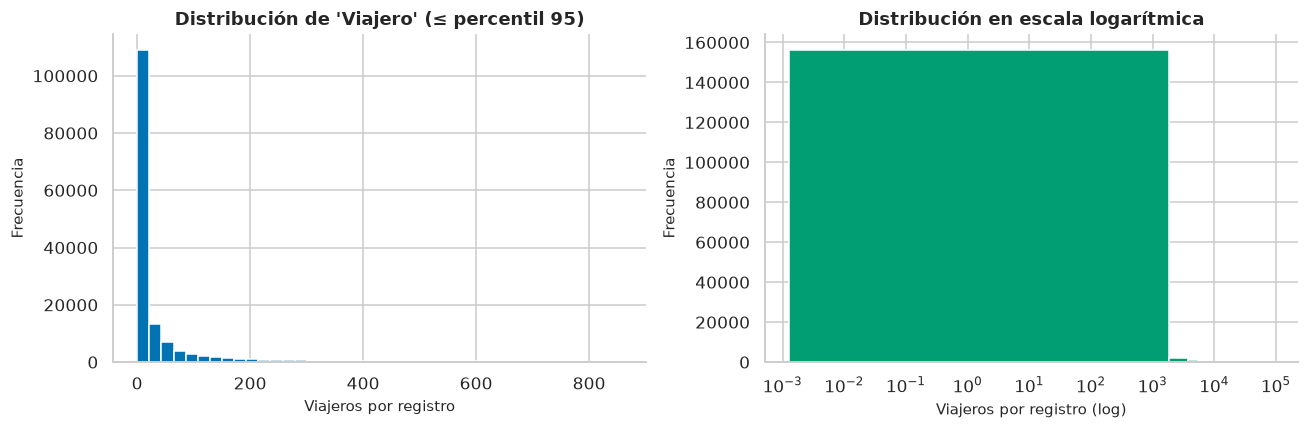

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# Histograma acotado (95% de los datos) para ver la masa
lim = df["Viajero"].quantile(0.95)
ax[0].hist(df.loc[df["Viajero"]<=lim, "Viajero"], bins=40, color=PAL[0])
ax[0].set(title="Distribución de 'Viajero' (≤ percentil 95)",
          xlabel="Viajeros por registro", ylabel="Frecuencia")
# Escala log para ver la cola pesada completa
ax[1].hist(df.loc[df["Viajero"]>0, "Viajero"], bins=50, color=PAL[2])
ax[1].set(title="Distribución en escala logarítmica", xlabel="Viajeros por registro (log)", ylabel="Frecuencia")
ax[1].set_xscale("log")
plt.tight_layout(); plt.show()

**Interpretación (descriptivas):**
- La medida `Viajero` es **fuertemente asimétrica a la derecha**: media **324.7** pero **mediana de solo 7**, con máximo de **92,336** y desviación estándar de **2,388**. El 75% de los registros tiene ≤ **38.9** viajeros. El histograma acotado confirma que la masa está en valores pequeños y la escala log revela una **cola larga**.
- **~0.03%** de ceros (prácticamente ninguno) y **~31.8%** de valores con decimales: estos últimos son **expansiones de encuesta**, no conteos enteros — coherente con la metodología de estimación.
- Por tipo, **Turista** domina tanto en registros (**117,912**) como en volumen (**37.6M** viajeros), seguido de **Excursionista** (9.07M), **Viajero** (4.47M) y **Cruceristas** (1.10M).

## 5. Comportamiento temporal  *(rubro a)*

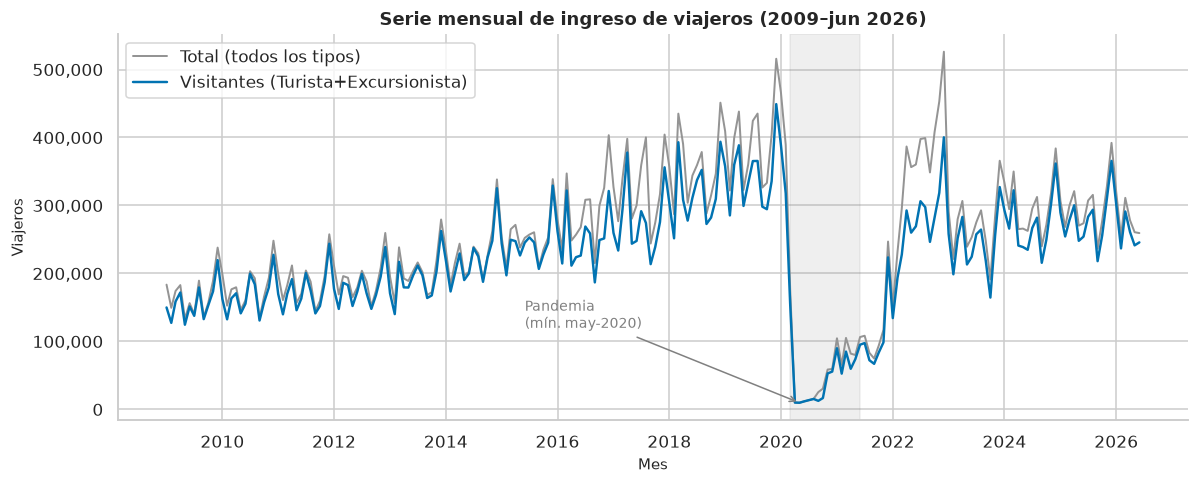

Pico mensual (visitantes):  Dec-2019  ->  449,114
Piso mensual (visitantes):  May-2020  ->  9,779


In [9]:
mensual_vis  = vis.groupby("fecha")["Viajero"].sum()
mensual_tot  = df.groupby("fecha")["Viajero"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mensual_tot.index, mensual_tot.values, lw=1.3, color=PAL[7], label="Total (todos los tipos)")
ax.plot(mensual_vis.index, mensual_vis.values, lw=1.6, color=PAL[0], label="Visitantes (Turista+Excursionista)")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="grey", alpha=0.12)
ax.annotate("Pandemia\n(mín. may-2020)", xy=(pd.Timestamp("2020-05-01"), 9779),
            xytext=(pd.Timestamp("2015-06-01"), 120000),
            arrowprops=dict(arrowstyle="->", color="grey"), color="grey", fontsize=9)
ax.set(title="Serie mensual de ingreso de viajeros (2009–jun 2026)",
       xlabel="Mes", ylabel="Viajeros")
ax.yaxis.set_major_formatter(MILES); ax.legend(); plt.tight_layout(); plt.show()

print(f"Pico mensual (visitantes):  {mensual_vis.idxmax():%b-%Y}  ->  {mensual_vis.max():,.0f}")
print(f"Piso mensual (visitantes):  {mensual_vis.idxmin():%b-%Y}  ->  {mensual_vis.min():,.0f}")

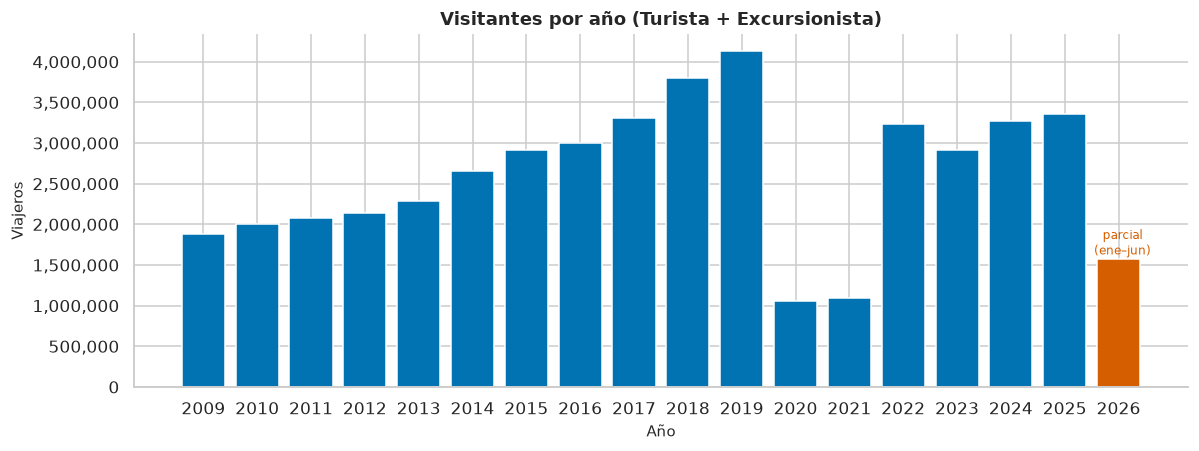

,visitantes
Año,
2009,1880183.0
2010,2004784.0
2011,2079715.0
2012,2139541.0
2013,2289703.0
2014,2660177.0
2015,2917886.0
2016,2997027.0
2017,3307651.0


In [10]:
anual_vis = vis.groupby("Año")["Viajero"].sum()
colores = [PAL[3] if a == 2026 else PAL[0] for a in anual_vis.index]  # 2026 parcial resaltado

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(anual_vis.index.astype(str), anual_vis.values, color=colores)
ax.set(title="Visitantes por año (Turista + Excursionista)", xlabel="Año", ylabel="Viajeros")
ax.yaxis.set_major_formatter(MILES)
ax.text(anual_vis.index.tolist().index(2026), anual_vis[2026], "  parcial\n  (ene–jun)",
        ha="center", va="bottom", fontsize=8, color=PAL[3])
plt.tight_layout(); plt.show()
display(anual_vis.round(0).to_frame("visitantes"))

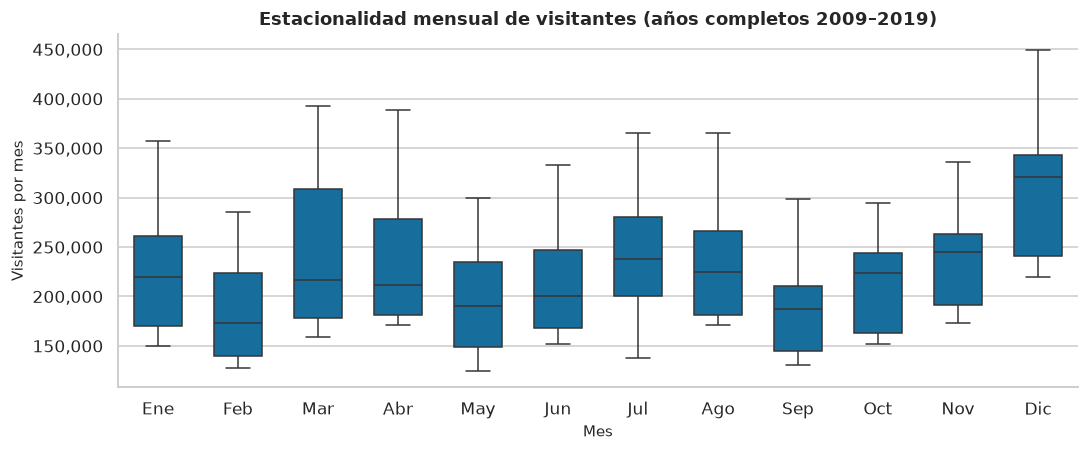

In [11]:
# Estacionalidad: distribución del total mensual por mes calendario (años completos 2009-2019)
base = vis[vis["Año"].between(2009, 2019)].groupby(["Año","Mes cod"])["Viajero"].sum().reset_index()
meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=base, x="Mes cod", y="Viajero", color=PAL[0], ax=ax, width=0.6, fliersize=2)
ax.set_xticks(range(12)); ax.set_xticklabels(meses)
ax.set(title="Estacionalidad mensual de visitantes (años completos 2009–2019)",
       xlabel="Mes", ylabel="Visitantes por mes")
ax.yaxis.set_major_formatter(MILES); plt.tight_layout(); plt.show()

**Interpretación (temporal):**
- Crecimiento **sostenido** de visitantes entre 2009 (**1.88M**) y **2019 (4.13M, máximo histórico)**.
- **Colapso pandémico**: 2020 cae a **1.06M** (−74% frente a 2019) y 2021 se mantiene en el piso (**1.10M**); el mínimo mensual absoluto es **mayo-2020 con 9,779** visitantes.
- **Recuperación** a partir de 2022 (**3.23M**); 2024–2025 rondan **3.3M**, todavía por debajo del pico de 2019.
- **2026 (barra resaltada) es parcial** (ene–jun, **1.58M**) y **no debe compararse** con años completos.
- **Estacionalidad marcada**: **diciembre** es el mes pico (vacaciones de fin de año; el máximo mensual absoluto fue **dic-2019 con 449,114**) y **febrero** el valle; marzo/julio también son altos (Semana Santa y verano). Este patrón estacional será clave para el modelado de series de tiempo.

## 6. Países con mayor cantidad de viajeros  *(rubro b)*

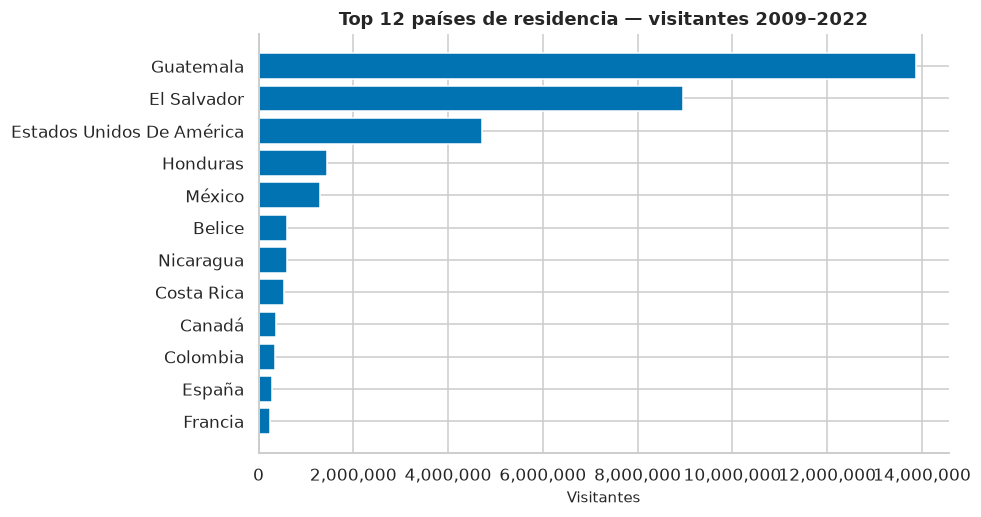

Los 3 primeros concentran el 77.4% de los visitantes 2009–2022.


In [12]:
# Ranking restringido a 2009-2022 por la ruptura de granularidad (país individual)
vis_pre = vis[vis["Año"].between(2009, 2022)]
top_pais = vis_pre.groupby("Pais_norm")["Viajero"].sum().sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top_pais.index[::-1], top_pais.values[::-1], color=PAL[0])
ax.set(title="Top 12 países de residencia — visitantes 2009–2022", xlabel="Visitantes")
ax.xaxis.set_major_formatter(MILES); plt.tight_layout(); plt.show()

share3 = top_pais.head(3).sum() / vis_pre["Viajero"].sum() * 100
print(f"Los 3 primeros concentran el {share3:.1f}% de los visitantes 2009–2022.")

In [13]:
# Desde 2023 la información se reporta por agrupaciones de mercado (no país individual)
vis_post = vis[vis["Año"] >= 2023]
top_agr = vis_post.groupby("Pais_norm")["Viajero"].sum().sort_values(ascending=False).head(10)
print("Top agrupaciones de mercado 2023–jun 2026:")
display(top_agr.round(0).to_frame("visitantes"))

Top agrupaciones de mercado 2023–jun 2026:


,visitantes
Pais_norm,
El Salvador,5120484.0
Estados Unidos De América,2257186.0
Honduras,1077471.0
México,374789.0
Costa Rica,330792.0
Belice,307110.0
Colombia,211368.0
Nicaragua,210373.0
Otros Países De América Del Sur,145827.0


**Interpretación (países):**
- En 2009–2022 dominan **Guatemala (13.9M)**, **El Salvador (8.96M)** y **Estados Unidos (4.71M)**, que juntos concentran el **77.4%** de los visitantes. *(“Guatemala” como país de **residencia** corresponde a nacionales/residentes que ingresan al país.)*
- El perfil refleja una **fuerte movilidad regional centroamericana** más el peso de la **diáspora en EE.UU.**; los mercados europeos (España, Francia, Alemania, Reino Unido) aparecen muy por debajo.
- El ranking se restringe a **2009–2022** porque **desde 2023** los datos se reportan por **agrupaciones de mercado** (27 grupos): allí lideran El Salvador, EE.UU. y Honduras, y los países pequeños se agregan en categorías como *“Otros Países de Europa”*. Mezclar ambos períodos a nivel de país sería inconsistente.

## 7. Regiones con mayor cantidad de viajeros  *(rubro c)*

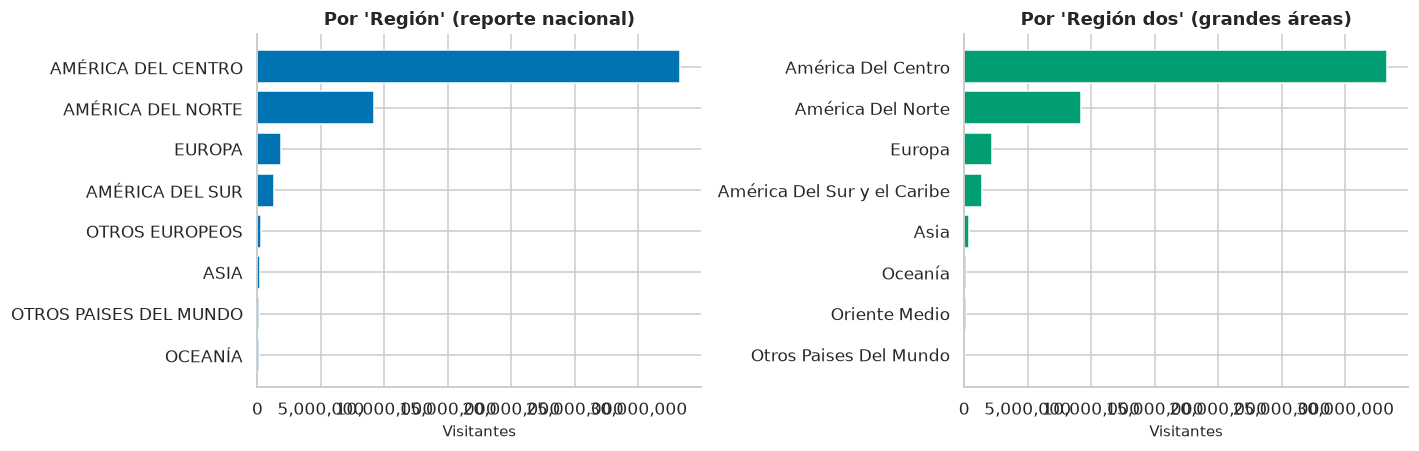

In [14]:
EXCL = ["Cruceristas", "Cruceros", "0"]
reg = (vis[~vis["Región"].isin(EXCL)]
       .groupby("Región")["Viajero"].sum().sort_values(ascending=False).head(8))
regdos = (vis[~vis["Región dos"].isin(EXCL)]
          .groupby("Región dos")["Viajero"].sum().sort_values(ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(reg.index[::-1], reg.values[::-1], color=PAL[0])
ax[0].set(title="Por 'Región' (reporte nacional)", xlabel="Visitantes"); ax[0].xaxis.set_major_formatter(MILES)
ax[1].barh(regdos.index[::-1], regdos.values[::-1], color=PAL[2])
ax[1].set(title="Por 'Región dos' (grandes áreas)", xlabel="Visitantes"); ax[1].xaxis.set_major_formatter(MILES)
plt.tight_layout(); plt.show()

**Interpretación (regiones):**
- **América Central / del Centro** domina de forma abrumadora con **~33.3M** visitantes, seguida muy de lejos por **América del Norte (~9.16M)** y **Europa (~1.85–2.15M)**.
- La concentración es coherente con el ranking de países: el turismo y la movilidad hacia Guatemala son **eminentemente regionales**. Asia, Oceanía y Oriente Medio aportan volúmenes marginales.

## 8. Vías de ingreso y fronteras más utilizadas  *(rubro d)*

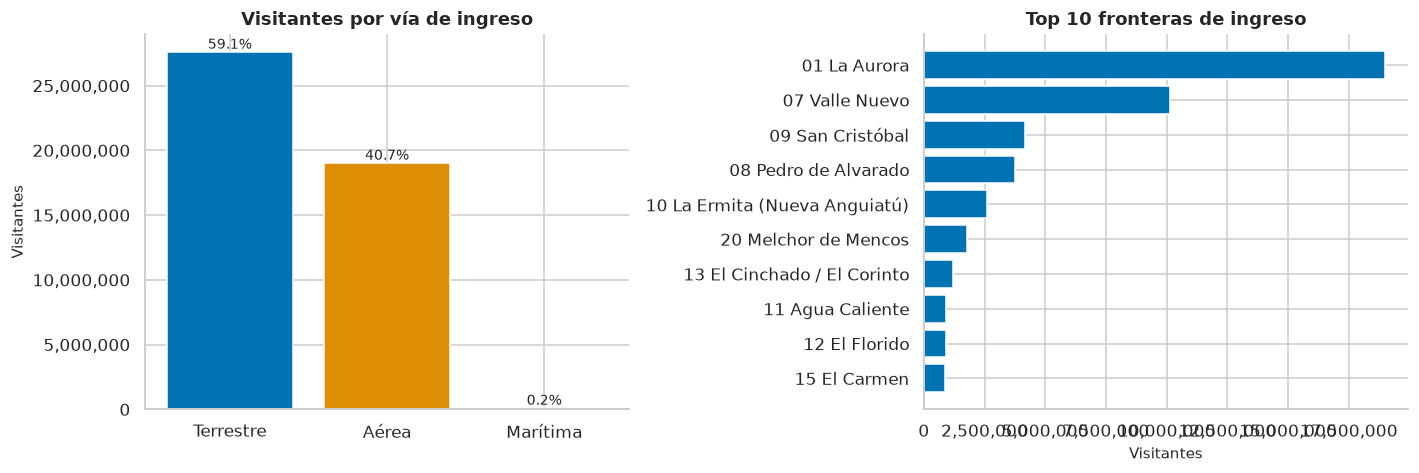

,% de visitantes
Vía,
Terrestre,59.1
Aérea,40.7
Marítima,0.2


In [15]:
via = vis.groupby("Vía")["Viajero"].sum().sort_values(ascending=False)
via_pct = via / via.sum() * 100
front = vis.groupby("Frontera")["Viajero"].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].bar(via.index, via.values, color=[PAL[0], PAL[1], PAL[2]])
ax[0].set(title="Visitantes por vía de ingreso", ylabel="Visitantes")
ax[0].yaxis.set_major_formatter(MILES)
for i, (v, p) in enumerate(zip(via.values, via_pct.values)):
    ax[0].text(i, v, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
ax[1].barh(front.index[::-1], front.values[::-1], color=PAL[0])
ax[1].set(title="Top 10 fronteras de ingreso", xlabel="Visitantes"); ax[1].xaxis.set_major_formatter(MILES)
plt.tight_layout(); plt.show()
display(via_pct.round(1).to_frame("% de visitantes"))

**Interpretación (vías y fronteras):**
- La vía **Terrestre** es la principal con **59.1%** de los visitantes, seguida de la **Aérea (40.7%)**; la **Marítima es marginal (0.2%)** — además pierde detalle a partir de 2017 (nota metodológica).
- Entre fronteras, **01 La Aurora** (aeropuerto internacional, ~19.0M) es la más usada, seguida de **07 Valle Nuevo** (~10.1M, frontera con El Salvador) y **09 San Cristóbal** (~4.18M). El patrón combina la puerta aérea principal con los pasos terrestres hacia El Salvador y Honduras, consistente con el dominio regional observado.

## 9. Valores atípicos  *(rubro e)*

Q1=2.0  Q3=38.9  IQR=36.9  ->  cota superior (Q3+1.5·IQR) = 94.2
Registros 'atípicos' por IQR: 26,390 (16.4% de las filas)
pero concentran el 96.7% del total de viajeros.


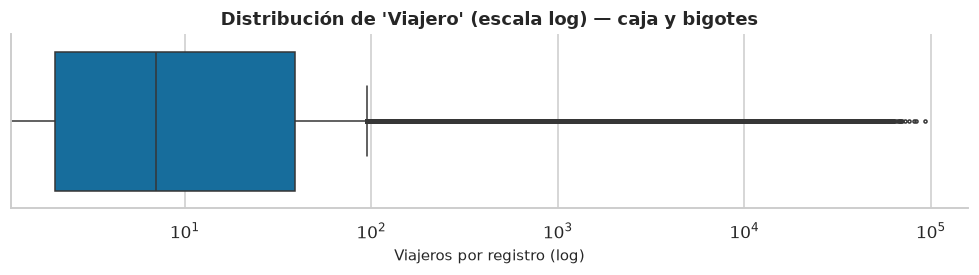

In [16]:
q1, q3 = df["Viajero"].quantile([0.25, 0.75])
iqr = q3 - q1
cota = q3 + 1.5 * iqr
out = df[df["Viajero"] > cota]

print(f"Q1={q1:.1f}  Q3={q3:.1f}  IQR={iqr:.1f}  ->  cota superior (Q3+1.5·IQR) = {cota:.1f}")
print(f"Registros 'atípicos' por IQR: {len(out):,} ({len(out)/len(df)*100:.1f}% de las filas)")
print(f"pero concentran el {out['Viajero'].sum()/df['Viajero'].sum()*100:.1f}% del total de viajeros.")

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.boxplot(x=df["Viajero"], color=PAL[0], ax=ax, fliersize=2)
ax.set_xscale("log"); ax.set(title="Distribución de 'Viajero' (escala log) — caja y bigotes", xlabel="Viajeros por registro (log)")
plt.tight_layout(); plt.show()

In [17]:
print("Top 10 registros por cantidad de viajeros:")
display(df.nlargest(10, "Viajero")[["Año","Mes","Vía","Frontera","Pais_norm","Tipo de Viajero","Viajero"]]
        .reset_index(drop=True)
        .style.format({"Viajero":"{:,.0f}"}))

Top 10 registros por cantidad de viajeros:


,Año,Mes,Vía,Frontera,Pais_norm,Tipo de Viajero,Viajero
0,2017,Ago,Terrestre,20 Melchor de Mencos,Belice,Viajero,"92,336"
1,2019,Dic,Aérea,01 La Aurora,Guatemala,Turista,"83,511"
2,2018,Dic,Aérea,01 La Aurora,Guatemala,Turista,"81,030"
3,2022,Dic,Aérea,01 La Aurora,Guatemala,Turista,"76,588"
4,2017,Dic,Aérea,01 La Aurora,Guatemala,Turista,"72,545"
5,2025,Dic,Terrestre,07 Valle Nuevo,El Salvador,Turista,"69,806"
6,2019,Nov,Aérea,01 La Aurora,Guatemala,Turista,"68,877"
7,2024,Dic,Terrestre,07 Valle Nuevo,El Salvador,Turista,"68,086"
8,2025,Dic,Aérea,01 La Aurora,Estados Unidos De América,Turista,"67,952"
9,2015,Dic,Aérea,01 La Aurora,Guatemala,Turista,"67,786"


**Interpretación (atípicos):**
- Con la regla IQR (cota superior **94.2**), **26,390 registros (16.4%)** se marcan como atípicos, pero **concentran el 96.7% del total de viajeros**. Esto es esperable en una distribución de **cola pesada**: los valores altos **no son errores**, sino las celdas legítimamente grandes (meses de países principales por el aeropuerto).
- Los máximos lo confirman: el récord es **Belice terrestre, ago-2017 (92,336)** en la categoría *Viajero* (tránsito/comercio fronterizo de alta frecuencia — justamente lo que la vista consistente excluye), seguido de **diciembres en La Aurora** con turistas guatemaltecos y estadounidenses (~68–84k). Reaparecen la **estacionalidad de diciembre** y la **concentración por aeropuerto**.
- **Decisión:** no se eliminan los atípicos — son la **señal** del fenómeno, no ruido. Para el modelado de series de tiempo conviene tratarlos vía **agregación mensual** y la vista Turista+Excursionista, más que recortarlos.

## 10. Conclusiones

1. **Calidad**: sin nulos ni duplicados exactos; se corrigieron **duplicados por casing** en `País` (235→222) y se documentaron categorías anómalas menores (`'0'`, `'0x2a'`, `'SIN ESPECIFICAR'` ≈ cruceristas).
2. **Distribución**: `Viajero` es muy asimétrica (mediana 7 vs. media 325), con decimales por expansión de encuesta; **Turista** es el tipo dominante.
3. **Temporal**: crecimiento 2009–2019, **colapso pandémico 2020–2021**, recuperación desde 2022 (aún bajo el pico de 2019) y **fuerte estacionalidad** con pico en diciembre y valle en febrero. **2026 es parcial.**
4. **Origen**: movilidad **regional centroamericana** + diáspora en EE.UU.; **77.4%** de visitantes en 3 países (2009–2022). América Central domina las regiones.
5. **Acceso**: predominio **terrestre (59%)** sobre aéreo (41%); La Aurora y Valle Nuevo son las fronteras clave.

### Implicaciones para el modelado de series de tiempo
- Usar la agregación **mensual de Turista + Excursionista** para una serie **consistente** en todo el rango.
- Modelar la **estacionalidad anual** (periodo 12) y contemplar las **rupturas estructurales**: pandemia (2020–2021) y cambio de metodología (2022→2023).
- **Excluir o tratar aparte 2026** (año incompleto) en cualquier comparación o pronóstico anual.